# Tutorial: ASE calculator

`AtomforgeCalculator` is an [ASE](https://ase-lib.org) calculator that
runs any installed atomforge model in that model’s own isolated
environment. Existing ASE scripts can switch to a foundation model by
changing the line that attaches the calculator.

This tutorial adapts ASE’s [equation of state
tutorial](https://docs.ase-lib.org/examples_generated/03-tutorials/eos_01.html).
That tutorial computes the energy of FCC silver at a few volumes with
ASE’s EMT potential and fits an equation of state to get the bulk
modulus.

The calculator requires the `ase` extra, `uv add "atomforge[ase]"`, plus
the plugins for the models you want to use.

## From EMT to foundation models

The three scripts below do the same calculation. The first is the ASE
tutorial adapted slightly: it collects volumes and energies in the loop
instead of writing a trajectory and reading it back. The second uses a
foundation model through atomforge. The third compares several
foundation models. Highlighted lines differ from the ASE version.

The ASE version with EMT:

``` python
import numpy as np
from ase import Atoms
from ase.calculators.emt import EMT
from ase.eos import EquationOfState
from ase.units import kJ

a = 4.0  # approximate lattice constant
b = a / 2
ag = Atoms("Ag", cell=[(0, b, b), (b, 0, b), (b, b, 0)], pbc=1)
ag.calc = EMT()
cell = ag.get_cell()

volumes, energies = [], []
for x in np.linspace(0.95, 1.05, 5):
    ag.set_cell(cell * x, scale_atoms=True)
    volumes.append(ag.get_volume())
    energies.append(ag.get_potential_energy())

eos = EquationOfState(volumes, energies)
v0, e0, B = eos.fit()
print(f"B = {B / kJ * 1.0e24:.1f} GPa")
eos.plot("Ag-eos.png")
```

The atomforge version with one model replaces the EMT import and the
calculator line:

``` python
from atomforge.ase import AtomforgeCalculator
from atomforge_orb import OrbV3

ag.calc = AtomforgeCalculator(OrbV3())
```

The version with several models shares one backend between the
calculators:

``` python
from atomforge.backend.subprocess import SubprocessBackend

with SubprocessBackend() as backend:
    for name, model in models.items():
        ag.calc = AtomforgeCalculator(model, backend=backend)
        ...  # the same loop and fit as above
```

With one model, the calculator creates its own backend on the first
calculation. That means starting a worker in the model’s environment and
loading the model. The backend shuts down when the calculator is
garbage-collected or the script ends. To shut it down at a known point,
call `calc.close()` or use the calculator as a context manager.

With several models, all the calculators share one `SubprocessBackend`.
The `with` block shuts down every worker at the end, and models that
share an environment also share a worker.

**Reuse calculators.** Attach one calculator to many structures rather
than creating a new calculator per structure. A calculator that owns its
backend starts a worker and loads the model on its first calculation, so
creating one per structure pays that cost every time. If you do need
many calculators, give them a shared backend as in the third script.

## Running the comparison

We now run all of them, with EMT as a reference, and plot the fitted
curves together. The structure setup and the loop are the same as in the
scripts above, wrapped in a function, with one change. The foundation
models predict a larger lattice constant than EMT, so their minima sit
at the edge of the original scan. We therefore extend the scan to larger
volumes and use more points.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from ase import Atoms
from ase.calculators.emt import EMT
from ase.eos import EquationOfState
from ase.units import kJ

from atomforge.ase import AtomforgeCalculator
from atomforge.backend.subprocess import SubprocessBackend
from atomforge_chgnet import CHGNet
from atomforge_mace import MACE
from atomforge_orb import OrbV3
from atomforge_sevennet import SevenNet

a = 4.0  # approximate lattice constant
b = a / 2
ag = Atoms("Ag", cell=[(0, b, b), (b, 0, b), (b, b, 0)], pbc=1)
cell = ag.get_cell()


def fit_eos(calc):
    ag.calc = calc
    volumes, energies = [], []
    for x in np.linspace(0.95, 1.07, 9):
        ag.set_cell(cell * x, scale_atoms=True)
        volumes.append(ag.get_volume())
        energies.append(ag.get_potential_energy())
    eos = EquationOfState(volumes, energies)
    eos.fit()
    return eos


models = {
    "Orb v3": OrbV3(),
    "MACE": MACE(),
    "SevenNet": SevenNet(),
    "CHGNet": CHGNet(),
}

fits = {"EMT": fit_eos(EMT())}
with SubprocessBackend() as backend:
    for name, model in models.items():
        fits[name] = fit_eos(AtomforgeCalculator(model, backend=backend))

For an FCC primitive cell with one atom, the cubic lattice constant is
$a_0 = (4 V_0)^{1/3}$.

In [2]:
print(f"{'':10s} {'a0 (Å)':>8s} {'B (GPa)':>8s}")
for name, eos in fits.items():
    a0 = (4 * eos.v0) ** (1 / 3)
    print(f"{name:10s} {a0:8.3f} {eos.B / kJ * 1.0e24:8.1f}")

             a0 (Å)  B (GPa)
EMT           4.064     99.8
Orb v3        4.145     86.3
MACE          4.165     85.0
SevenNet      4.165     89.4
CHGNet        4.157     90.0

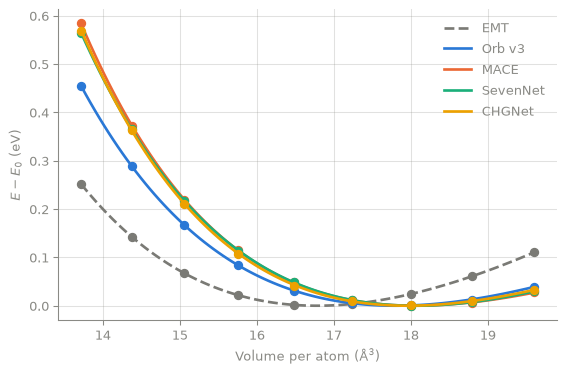

In [3]:
colors = {
    "EMT": "#7a7a75",
    "Orb v3": "#2a78d6",
    "MACE": "#eb6834",
    "SevenNet": "#1baf7a",
    "CHGNet": "#eda100",
}

# A mid-grey for text and axes reads on both the light and the dark docs theme,
# and a transparent background lets the page colour show through.
ink = "#8a8a85"
plt.rcParams.update(
    {
        "text.color": ink,
        "axes.labelcolor": ink,
        "axes.edgecolor": ink,
        "xtick.color": ink,
        "ytick.color": ink,
        "grid.color": ink,
    }
)

fig, ax = plt.subplots(figsize=(6, 4))
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)
for name, eos in fits.items():
    _, e0, _, _, v_fit, e_fit, v, e = eos.getplotdata()
    linestyle = "--" if name == "EMT" else "-"
    ax.plot(v_fit, e_fit - e0, color=colors[name], lw=2, ls=linestyle, label=name)
    ax.plot(v, np.asarray(e) - e0, "o", color=colors[name], ms=6)

ax.set_xlabel("Volume per atom (Å$^3$)")
ax.set_ylabel("$E - E_0$ (eV)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()

The models disagree noticeably with each other and with EMT. EMT is
fitted to silver’s experimental properties, while the foundation models
are trained on DFT data and inherit its functional’s errors. Comparisons
like this, run with an unchanged ASE script, are where atomforge is
meant to help.